# 03 — Feature Engineering
**Week 2, Steps 8–10**

Builds the Analytical Base Table (one row per order), engineers 15+ features,
and builds customer-level features as-of a date.

> Run **Restart & Run All** to reproduce from scratch.


In [1]:
# Run from the project root (works from notebooks/ too)
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
print("Working directory:", Path.cwd())

Working directory: /Users/cloudanix/Sahil/Sakshi/Project/Zomato_Business_Intelligence


In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (10, 4)

from src.ingest import load_all
from src.clean import CleaningLog, DataCleaner, CITY_ALIASES
from src.features import build_analytical_base_table, add_features, build_customer_features

rng = np.random.default_rng(42)  # seeded RNG for reproducibility (PRD requirement)
pd.set_option('display.max_columns', 20)

print("Libraries loaded ✅")


Libraries loaded ✅


## 1. Build cleaned tables

In [3]:
raw         = load_all()
cities_list = raw['cities']['city'].dropna().str.strip().tolist()
log         = CleaningLog()
cleaner     = DataCleaner(cities_list, CITY_ALIASES, log)
cleaned     = cleaner.clean_all(raw)
print(f"Cleaned: {len(cleaned)} tables  |  orders: {len(cleaned['orders']):,}")


Cleaned: 12 tables  |  orders: 20,475


## 2. Build Analytical Base Table

In [4]:
n_orders = len(cleaned['orders'])
abt_raw = build_analytical_base_table(cleaned)
assert len(abt_raw) == n_orders, f"Row count changed! {n_orders} → {len(abt_raw)}"
print(f"ABT: {len(abt_raw):,} rows × {len(abt_raw.columns)} cols  (one row per order ✅)")


ABT: 20,475 rows × 70 cols  (one row per order ✅)


## 3. Engineer features

In [5]:
abt = add_features(abt_raw)
assert len(abt) == n_orders
print(f"ABT with features: {len(abt):,} rows × {len(abt.columns)} cols")


ABT with features: 20,475 rows × 85 cols


## 4. Feature catalogue

In [6]:
feature_catalogue = [
    ("peak_hour",                  "Binary 0/1 — order placed in lunch (12-14) or dinner (19-22) peak"),
    ("weekend_order",              "Binary 0/1 — order placed on Saturday or Sunday"),
    ("rain_impact",                "Ordinal: None/Light/Moderate/Heavy — from rainfall mm"),
    ("traffic_score",              "Numeric 1-4 (Low/Moderate/High/Severe) — from traffic join on city+date+hour"),
    ("customer_tenure_days",       "Days between customer registration and this order"),
    ("restaurant_popularity_rank", "Dense rank of restaurant by order count within its city"),
    ("delivery_efficiency",        "Partner avg_delivery_time ÷ city average — below 1 = faster than city"),
    ("average_rating",             "Mean of 3 feedback ratings — EDA/BI only, NOT a delivery-time model input"),
    ("n_items",                    "Total items in this order (sum of quantity from order_items)"),
    ("discount_pct",               "discount ÷ food_cost — fraction of order discounted"),
    ("partner_tenure_days",        "Days from partner joining_date to order_date"),
    ("is_peak_and_rain",           "Interaction: peak_hour=1 AND rain_impact in Moderate/Heavy"),
    ("is_weekend_and_rain",        "Interaction: weekend_order=1 AND rain_impact in Moderate/Heavy"),
    ("coupon_used",                "Binary 0/1 — whether a coupon was applied"),
    ("distance_to_city_centre_km", "Haversine km from restaurant to mean lat/lon of city's restaurants (proxy — no customer coords)"),
    ("is_cross_city",              "Binary 0/1 — customer city ≠ restaurant city"),
    ("avg_prep_time",              "Mean preparation time (mins) across items in this order"),
    ("max_prep_time",              "Max preparation time (mins) across items in this order"),
    ("dt_outlier_flag",            "IQR k=3.0 outlier flag on delivery_time_minutes — flagged, not capped"),
]

pd.DataFrame(feature_catalogue, columns=['feature','description'])


,feature,description
0,peak_hour,Binary 0/1 — order placed in lunch (12-14) or ...
1,weekend_order,Binary 0/1 — order placed on Saturday or Sunday
2,rain_impact,Ordinal: None/Light/Moderate/Heavy — from rain...
3,traffic_score,Numeric 1-4 (Low/Moderate/High/Severe) — from ...
4,customer_tenure_days,Days between customer registration and this order
5,restaurant_popularity_rank,Dense rank of restaurant by order count within...
6,delivery_efficiency,Partner avg_delivery_time ÷ city average — bel...
7,average_rating,"Mean of 3 feedback ratings — EDA/BI only, NOT ..."
8,n_items,Total items in this order (sum of quantity fro...
9,discount_pct,discount ÷ food_cost — fraction of order disco...


## 5. Feature distributions — key plots

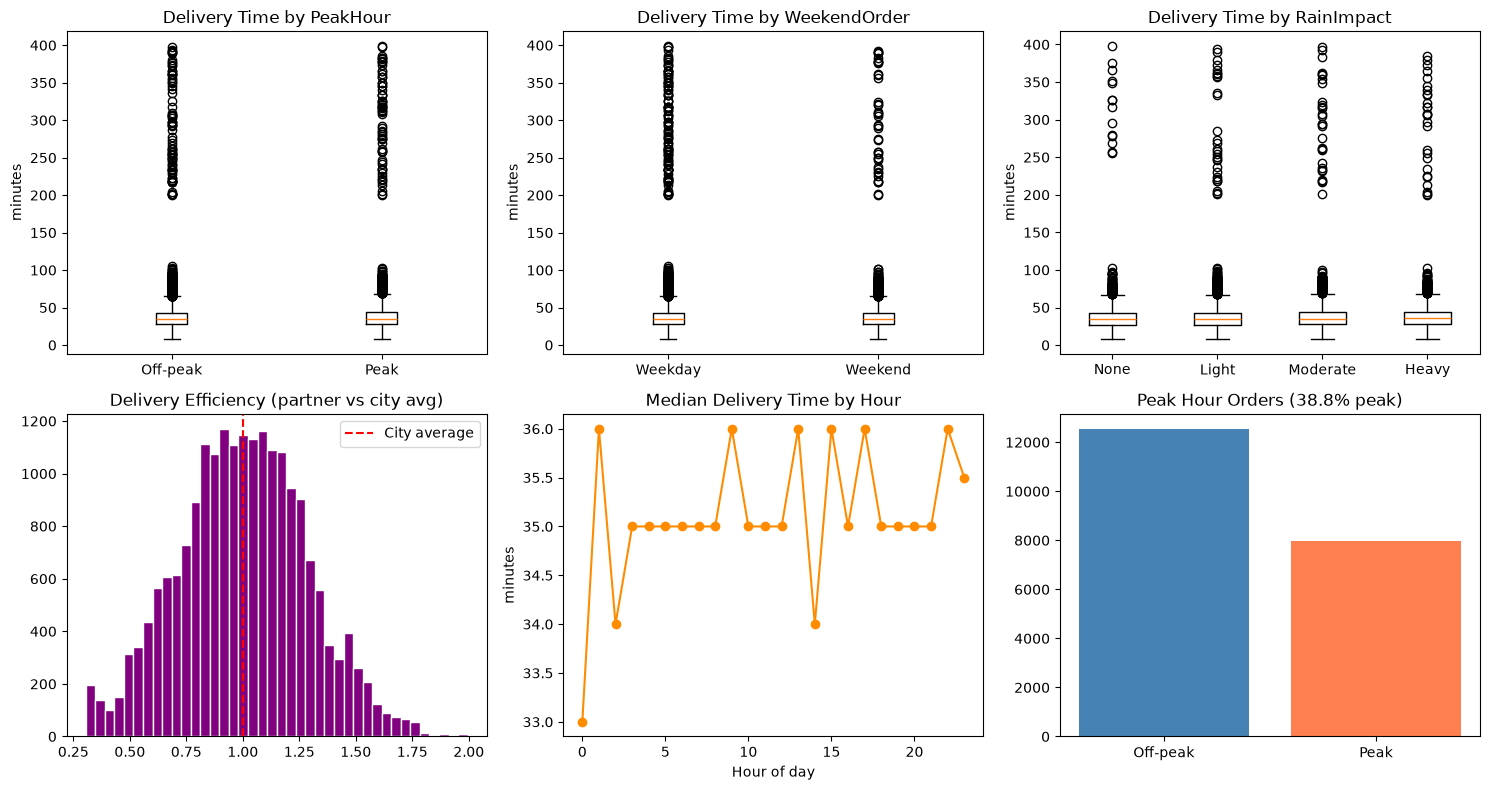

Plot saved → reports/feature_distributions.png


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# 5a: Delivery time by PeakHour
peak_data = [
    abt.loc[abt['peak_hour']==0,'delivery_time_minutes'].dropna(),
    abt.loc[abt['peak_hour']==1,'delivery_time_minutes'].dropna()
]
axes[0,0].boxplot(peak_data, tick_labels=['Off-peak','Peak'])
axes[0,0].set_title('Delivery Time by PeakHour')
axes[0,0].set_ylabel('minutes')

# 5b: Delivery time by WeekendOrder
wk_data = [
    abt.loc[abt['weekend_order']==0,'delivery_time_minutes'].dropna(),
    abt.loc[abt['weekend_order']==1,'delivery_time_minutes'].dropna()
]
axes[0,1].boxplot(wk_data, tick_labels=['Weekday','Weekend'])
axes[0,1].set_title('Delivery Time by WeekendOrder')
axes[0,1].set_ylabel('minutes')

# 5c: Delivery time by RainImpact
rain_order = ['None','Light','Moderate','Heavy']
rain_data = [abt.loc[abt['rain_impact']==r,'delivery_time_minutes'].dropna()
             for r in rain_order]
axes[0,2].boxplot([d for d in rain_data if len(d)>0],
                  tick_labels=[r for r, d in zip(rain_order, rain_data) if len(d)>0])
axes[0,2].set_title('Delivery Time by RainImpact')
axes[0,2].set_ylabel('minutes')

# 5d: Delivery efficiency histogram
axes[1,0].hist(abt['delivery_efficiency'].dropna(), bins=40, color='purple', edgecolor='white')
axes[1,0].axvline(1.0, color='red', linestyle='--', label='City average')
axes[1,0].set_title('Delivery Efficiency (partner vs city avg)')
axes[1,0].legend()

# 5e: Delivery time by order_hour (hourly median)
hourly = abt.groupby('order_hour')['delivery_time_minutes'].median()
axes[1,1].plot(hourly.index, hourly.values, marker='o', color='darkorange')
axes[1,1].set_title('Median Delivery Time by Hour')
axes[1,1].set_xlabel('Hour of day')
axes[1,1].set_ylabel('minutes')

# 5f: Peak hour share
peak_counts = abt['peak_hour'].value_counts().sort_index()
axes[1,2].bar(['Off-peak','Peak'], peak_counts.values, color=['steelblue','coral'])
axes[1,2].set_title(f'Peak Hour Orders ({abt["peak_hour"].mean()*100:.1f}% peak)')

plt.tight_layout()
plt.savefig('reports/feature_distributions.png', dpi=100, bbox_inches='tight')
plt.show()
print("Plot saved → reports/feature_distributions.png")


## 6. GroupBy, pivot, and cross-tab summaries (PRD NumPy/Pandas requirements)

In [8]:
# PRD requirement: cross-tabulation
print("=== Cross-tab: membership × order_status ===")
ct = pd.crosstab(abt['membership'], abt['order_status'])
print(ct)


=== Cross-tab: membership × order_status ===
order_status  Cancelled  Delivered  Delivered Late  Food Not Delivered
membership                                                            
Basic              2673       6680            1262                1456
Gold                906       2203             414                 430
Zomato Pro          952       2398             454                 452


In [9]:
# PRD requirement: pivot table
print("\n=== Pivot: restaurant_city × order_status (mean delivery time) ===")
pv = abt.pivot_table(
    values='delivery_time_minutes',
    index='restaurant_city',
    columns='order_status',
    aggfunc='mean'
).round(1)
pv.head(5)



=== Pivot: restaurant_city × order_status (mean delivery time) ===


order_status,Cancelled,Delivered,Delivered Late,Food Not Delivered
restaurant_city,,,,
Ahmedabad,34.5,34.9,64.3,35.4
Bengaluru,37.1,35.2,62.4,34.0
Bhopal,34.0,36.4,67.0,33.7
Bhubaneswar,35.9,36.3,64.9,37.9
Chandigarh,32.8,33.7,60.7,36.5


In [10]:
# PRD requirement: GroupBy summary
print("=== GroupBy: avg delivery time by vehicle_type ===")
abt.groupby('vehicle_type')['delivery_time_minutes'].agg(['mean','median','count']).round(2)


=== GroupBy: avg delivery time by vehicle_type ===


,mean,median,count
vehicle_type,,,
Bicycle,38.03,35.0,1954
Bike,38.52,35.0,11421
Car,38.66,35.0,1878
Scooter,38.95,35.0,5015


## 7. Categorical encoding demo (ordinal + get_dummies)

In [11]:
# Ordinal encoding for traffic_level (already done as traffic_score)
# Demo pd.get_dummies for nominal columns — real encoding goes in Week 3 pipeline
sample = abt[['membership','order_status','restaurant_cuisine']].head(5)
print("One-hot encoding demo (real encoding in Week 3 sklearn pipeline):")
pd.get_dummies(sample, columns=['membership','order_status'], drop_first=True)


One-hot encoding demo (real encoding in Week 3 sklearn pipeline):


,restaurant_cuisine,membership_Gold,membership_Zomato Pro,order_status_Delivered,order_status_Food Not Delivered
0,Mexican,False,False,True,False
1,Sushi,False,True,False,True
2,NaN,False,False,False,False
3,Mexican,True,False,True,False
4,Healthy Food,False,False,True,False


## 8. CustomerTenure negative check

In [12]:
neg_tenure = abt['customer_tenure_days'] < 0
print(f"Orders with negative customer tenure (order before registration): {neg_tenure.sum():,}")
print("These rows are flagged via 'tenure_is_negative' column and will be")
print("excluded from model features in Week 3 (not from the dataset entirely).")
abt[neg_tenure][['order_id','customer_id','order_date','registration_date','customer_tenure_days']].head()


Orders with negative customer tenure (order before registration): 6,832
These rows are flagged via 'tenure_is_negative' column and will be
excluded from model features in Week 3 (not from the dataset entirely).


,order_id,customer_id,order_date,registration_date,customer_tenure_days
0,100001,7095,2023-06-17,2024-06-19,-368
2,100003,11040,2023-05-09,2024-05-31,-388
8,100009,10709,2023-11-11,2024-12-02,-387
9,100010,1385,2023-03-15,2024-01-06,-297
10,100011,4236,2023-05-13,2024-11-01,-538


## 9. Percentile stats (PRD NumPy requirement)

In [13]:
valid_dt = abt['delivery_time_minutes'].dropna()
pcts = np.percentile(valid_dt, [50, 75, 90, 95, 99, 99.9])
print("Delivery time percentiles (valid orders):")
for p, v in zip([50,75,90,95,99,99.9], pcts):
    print(f"  p{p:<5}  {v:.1f} min")
print(f"\nLate delivery threshold (p75): {pcts[1]:.0f} min")
print("→ This matches kpi_definitions.md: 'late' = delivery_time_minutes > 45")


Delivery time percentiles (valid orders):
  p50     35.0 min
  p75     43.0 min
  p90     55.0 min
  p95     67.0 min
  p99     89.0 min
  p99.9   370.4 min

Late delivery threshold (p75): 43 min
→ This matches kpi_definitions.md: 'late' = delivery_time_minutes > 45


## 10. Customer features as-of reference date (Step 10)

In [14]:
orders_clean = cleaned['orders'].copy()
orders_clean['order_date']   = pd.to_datetime(orders_clean['order_date'], errors='coerce')
orders_clean['final_amount'] = pd.to_numeric(orders_clean['final_amount'], errors='coerce')

ref_date = orders_clean['order_date'].max()
cust_features = build_customer_features(orders_clean, as_of=ref_date)

print(f"Reference date: {ref_date.date()} (never CURRENT_DATE — the data is a fixed snapshot)")
print(f"Customers with at least 1 delivered order: {len(cust_features):,}")
print(f"Active (≤60 days since last order): {(cust_features['days_since_last_order']<=60).sum():,}")
print(f"Churned (>60 days): {(cust_features['days_since_last_order']>60).sum():,}\n")
print("Why the cut-off date matters:")
print("  Week 3 will call build_customer_features(orders, as_of=cutoff) with an")
print("  earlier date, then label customers as churned if they didn't order in")
print("  the following 60 days. If we used all data, the model would see the")
print("  future orders it is supposed to predict.")
cust_features.describe().round(2)


Reference date: 2024-12-31 (never CURRENT_DATE — the data is a fixed snapshot)
Customers with at least 1 delivered order: 8,818
Active (≤60 days since last order): 1,216
Churned (>60 days): 7,602

Why the cut-off date matters:
  Week 3 will call build_customer_features(orders, as_of=cutoff) with an
  earlier date, then label customers as churned if they didn't order in
  the following 60 days. If we used all data, the model would see the
  future orders it is supposed to predict.


,customer_id,orders_to_date,customer_lifetime_value,average_basket_value,first_order,last_order,days_since_last_order,order_frequency_30d
count,8818.0,8818.0,8818.00,8761.00,8818,8818,8818.00,8818.0
mean,5983.1,1.8,696.54,391.89,2023-10-12 06:52:59.496484608,2024-03-16 21:59:09.376275712,289.08,0.25
min,2.0,1.0,0.00,33.00,2023-01-01 00:00:00,2023-01-01 00:00:00,0.00,0.04
25%,2966.25,1.0,370.75,299.73,2023-04-20 00:00:00,2023-10-15 00:00:00,114.00,0.08
50%,5935.5,2.0,587.42,386.50,2023-09-07 00:00:00,2024-04-19 00:00:00,256.00,0.12
75%,9009.75,2.0,929.44,477.00,2024-03-13 00:00:00,2024-09-08 00:00:00,443.00,0.19
max,11999.0,7.0,3919.40,976.30,2024-12-31 00:00:00,2024-12-31 00:00:00,730.00,30.0
std,3465.42,0.97,439.18,136.81,NaN,NaN,202.55,1.26


## 11. Distance limitation note

In [15]:
print("=== Distance feature: honest proxy ===")
print()
print("customers.csv has no latitude/longitude columns (verified in Step 9).")
print("The PRD's 'restaurant-to-customer distance' was replaced with:")
print()
print("  distance_to_city_centre_km = haversine_km(")
print("      restaurant.lat, restaurant.lon,")
print("      mean(lat for all restaurants in same city),")
print("      mean(lon for all restaurants in same city)")
print("  )")
print()
print("This is a proxy, not the actual delivery distance.")
print("Documented in documentation/kpi_definitions.md and validation_report.md.")
print()
dist = abt['distance_to_city_centre_km'].dropna()
print(f"  min={dist.min():.1f} km  median={dist.median():.1f} km  max={dist.max():.1f} km")


=== Distance feature: honest proxy ===

customers.csv has no latitude/longitude columns (verified in Step 9).
The PRD's 'restaurant-to-customer distance' was replaced with:

  distance_to_city_centre_km = haversine_km(
      restaurant.lat, restaurant.lon,
      mean(lat for all restaurants in same city),
      mean(lon for all restaurants in same city)
  )

This is a proxy, not the actual delivery distance.
Documented in documentation/kpi_definitions.md and validation_report.md.

  min=9.9 km  median=943.7 km  max=1860.7 km


## 12. Final ABT shape

In [16]:
print(f"=== Analytical Base Table ===")
print(f"  Rows:    {len(abt):,}  (one per cleaned order ✅)")
print(f"  Columns: {len(abt.columns)}")
print()
print("Column groups:")
for label, cols in [
    ("Order",        [c for c in abt.columns if c.startswith("order_") or c in ["order_id","final_amount","food_cost","delivery_fee","gst","coupon_code","discount","payment_method","order_status","dt_outlier_flag"]]),
    ("Customer",     [c for c in abt.columns if c.startswith("customer_") or c in ["membership","registration_date","state","preferred_cuisine","total_orders","tenure_is_negative","customer_tenure_days"]]),
    ("Restaurant",   [c for c in abt.columns if c.startswith("restaurant_") or c in ["area","average_cost","latitude","longitude","city_lat","city_lon","distance_to_city_centre_km","is_cross_city","restaurant_order_count","restaurant_popularity_rank"]]),
    ("Partner",      [c for c in abt.columns if c.startswith("partner_") or c in ["vehicle_type","completed_deliveries","delivery_efficiency"]]),
    ("Features",     ["peak_hour","weekend_order","rain_impact","traffic_score","is_peak_and_rain","is_weekend_and_rain","coupon_used","order_hour","order_minute","order_dayofweek","order_month"]),
    ("Basket",       ["n_items","n_distinct_items","basket_value","avg_prep_time","max_prep_time","discount_pct"]),
    ("Weather",      ["temperature","rainfall","humidity","weather_condition"]),
    ("Traffic",      ["traffic_level","traffic_score","average_speed"]),
    ("Feedback",     [c for c in abt.columns if c.startswith("feedback_") or c in ["review","sentiment","has_review"]]),
]:
    found = [c for c in cols if c in abt.columns]
    if found:
        print(f"  {label:<12} ({len(found):>2}): {', '.join(found[:6])}{'...' if len(found)>6 else ''}")


=== Analytical Base Table ===
  Rows:    20,475  (one per cleaned order ✅)
  Columns: 85

Column groups:
  Order        (16): order_id, order_date, order_time, food_cost, delivery_fee, discount...
  Customer     (12): customer_id, customer_name, customer_age, customer_gender, customer_city, state...
  Restaurant   (16): restaurant_id, restaurant_name, restaurant_cuisine, restaurant_city, area, restaurant_rating...
  Partner      (10): partner_name, partner_age, partner_gender, vehicle_type, partner_city, partner_rating...
  Features     (11): peak_hour, weekend_order, rain_impact, traffic_score, is_peak_and_rain, is_weekend_and_rain...
  Basket       ( 6): n_items, n_distinct_items, basket_value, avg_prep_time, max_prep_time, discount_pct
  Weather      ( 4): temperature, rainfall, humidity, weather_condition
  Traffic      ( 3): traffic_level, traffic_score, average_speed
  Feedback     ( 6): feedback_customer_rating, feedback_delivery_rating, feedback_food_rating, review, sentiment, 